In [1]:
# !git clone https://github.com/LoryPack/GenerativeNetworksScoringRulesProbabilisticForecasting.git
!git clone https://github.com/thuthiminhnguyen/PF-GN-SR.git
# %cd GenerativeNetworksScoringRulesProbabilisticForecasting
%cd PF-GN-SR
!pip install -r requirements.txt

Cloning into 'PF-GN-SR'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 35 (delta 9), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 10.49 MiB | 27.96 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/kaggle/working/PF-GN-SR
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 63.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
ERROR: Exception:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 377, in run
    requirement_set = resolver.resol

In [2]:
!pip install typeguard==2.13.3 torchtyping
!python generate_data.py
!python train_nn.py
!python predict_test_plot.py
!python predict_test_plot_comparison.py

  Attempting uninstall: typeguard
    Found existing installation: typeguard 4.6.0
    Uninstalling typeguard-4.6.0:
      Successfully uninstalled typeguard-4.6.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.18.4 requires typeguard<5,>=4, but you have typeguard 2.13.3 which is incompatible.
inflect 7.5.0 requires typeguard>=4.0.1, but you have typeguard 2.13.3 which is incompatible.
usage: generate_data.py [-h] [--root_folder ROOT_FOLDER]
                        [--model_folder MODEL_FOLDER]
                        [--datasets_folder DATASETS_FOLDER]
                        [--n_steps N_STEPS] [--spinup_steps SPINUP_STEPS]
                        [--seed SEED] [--window_size WINDOW_SIZE]
                        [--not_save_observations]
                        {lorenz,lorenz96,WeatherBench}
generate_data.py: error: the following arguments 

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from typeguard.importhook import install_import_hook
import scipy.stats as stats
from numpy.lib.stride_tricks import sliding_window_view
import arviz as az
from scipy.integrate import solve_ivp

In [4]:
# Set seed for reproducibility
np.random.seed(10)

# -------------------------------------------------------------
# 1. Define Lorenz63 ODE System
# -------------------------------------------------------------
def lorenz63(t, state, s=10.0, r=28.0, b=2.667):
    x, y, z = state
    dx = s * (y - x)
    dy = x * (r - z) - y
    dz = x * y - b * z
    return [dx, dy, dz]

# Parameters & initial state
parameters = {"s": 10.0, "r": 28.0, "b": 2.667}
state0 = [0.0, 1.0, 1.05]

# Times: seq(0, by = 0.01, length.out = 5000)
dt = 0.01
n_steps = 5000
t_eval = np.arange(0, n_steps) * dt  # shape: (5000,)
t_span = (t_eval[0], t_eval[-1])

# -------------------------------------------------------------
# 2. Solve ODE (Equivalent to deSolve::ode)
# -------------------------------------------------------------
# method='LSODA' matches R's default deSolve ode solver
sol = solve_ivp(
    fun=lambda t, y: lorenz63(t, y, **parameters),
    t_span=t_span,
    y0=state0,
    t_eval=t_eval,
    method="LSODA"
)

# Create DataFrame (sol.y has shape (3, 5000) -> [x, y, z])
lr63_df = pd.DataFrame({
    "time": sol.t,
    "x": sol.y[0],
    "y": sol.y[1],
    "z": sol.y[2]
})

# -------------------------------------------------------------
# 3. Add Observational Noise
# -------------------------------------------------------------
noise_level = 0.1  # 10% noise

# Option A: Scaled by max(|y|) (Matches your thesis formula)
noise_sd = noise_level * np.max(np.abs(lr63_df["y"]))

# Option B: Scaled by standard deviation of y (Alternative standard SNR)
# noise_sd = noise_level * np.std(lr63_df["y"])

# Keep clean y for ground-truth comparison and create noisy y
lr63_df["y_clean"] = lr63_df["y"]
lr63_df["y_noisy"] = lr63_df["y_clean"] + np.random.normal(loc=0.0, scale=noise_sd, size=len(lr63_df))

# -------------------------------------------------------------
# 4. Inspect Results
# -------------------------------------------------------------
print("Shape of DataFrame:", lr63_df.shape)
print("\nFirst 6 rows (equivalent to head(lr63_df)):")
print(lr63_df.head())

Shape of DataFrame: (5000, 6)

First 6 rows (equivalent to head(lr63_df)):
   time         x         y         z   y_clean   y_noisy
0  0.00  0.000000  1.000000  1.050000  1.000000  4.626708
1  0.01  0.095096  1.003048  1.022846  1.003048  2.951181
2  0.02  0.182638  1.030526  0.997328  1.030526 -3.178525
3  0.03  0.265570  1.080614  0.973421  1.080614  1.057780
4  0.04  0.346437  1.152219  0.951177  1.152219  2.844489


In [5]:
timeseries = lr63_df["y_noisy"].to_numpy().reshape(-1, 1)

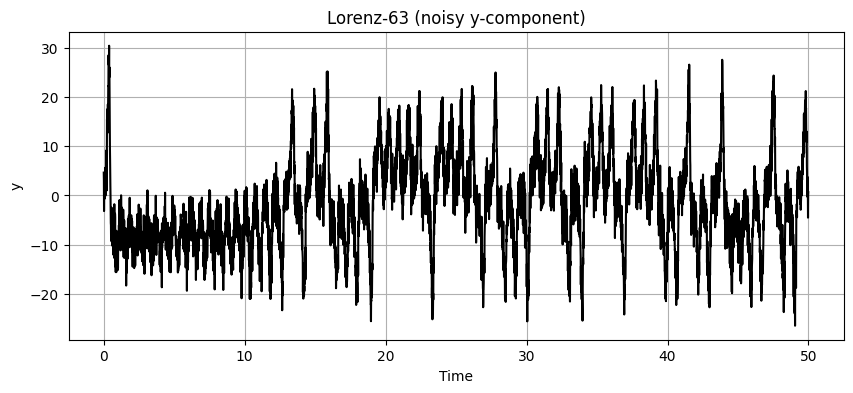

In [6]:
all_t = lr63_df["time"]
plt.figure(figsize=(10, 4))
plt.plot(all_t, timeseries, color="black")
plt.xlabel("Time")
plt.ylabel("y")
plt.title("Lorenz-63 (noisy y-component)")
plt.grid(True)
plt.savefig("lorenz63_noisy.pdf", bbox_inches="tight")
plt.show()

In [7]:
timeseries[0:10]

array([[ 4.62670788],
       [ 2.95118138],
       [-3.17852488],
       [ 1.05777961],
       [ 2.84448928],
       [-0.71631706],
       [ 2.0819535 ],
       [ 1.7902639 ],
       [ 1.66509051],
       [ 1.36115463]])

In [8]:
#!/bin/bash
# This scripts shows how to reproduce experiments for Lorenz63 model.

# create folders:
!mkdir results
!mkdir results/lorenz
!mkdir results/lorenz/datasets

timeseries_stacked = None
window_size = 10
if timeseries_stacked is None:  # if that is not created above (as for the Lorenz96)
    timeseries_stacked = np.lib.stride_tricks.sliding_window_view(timeseries, window_shape=window_size + 1,
                                                                  axis=0).transpose(0, 2, 1)

# Then, we can split in input, target as follows:
input_data = timeseries_stacked[:, 0:-1]
target_data = timeseries_stacked[:, -1]
n_samples = input_data.shape[0]
print("Total number of samples:", n_samples)

# train/validate/test (60-20-20) split, in order (not shuffling):
n_train = int(0.6 * n_samples)
n_val = int(0.2 * n_samples)-1
n_test = n_samples - n_val - n_train

input_data_train = input_data[0:n_train]
target_data_train = target_data[0:n_train]
input_data_val = input_data[n_train:n_train + n_val]
target_data_val = target_data[n_train:n_train + n_val]
input_data_test = input_data[n_train + n_val:n_samples]
target_data_test = target_data[n_train + n_val:n_samples]

# convert to torch:
input_data_train = torch.from_numpy(np.float32(input_data_train))
target_data_train = torch.from_numpy(np.float32(target_data_train))
input_data_val = torch.from_numpy(np.float32(input_data_val))
target_data_val = torch.from_numpy(np.float32(target_data_val))
input_data_test = torch.from_numpy(np.float32(input_data_test))
target_data_test = torch.from_numpy(np.float32(target_data_test))

torch.save(input_data_train, "/kaggle/working/PF-GN-SR/results/lorenz/datasets/train_x.pty")
torch.save(target_data_train, "/kaggle/working/PF-GN-SR/results/lorenz/datasets/train_y.pty")
torch.save(input_data_val, "/kaggle/working/PF-GN-SR/results/lorenz/datasets/val_x.pty")
torch.save(target_data_val, "/kaggle/working/PF-GN-SR/results/lorenz/datasets/val_y.pty")
torch.save(input_data_test, "/kaggle/working/PF-GN-SR/results/lorenz/datasets/test_x.pty")
torch.save(target_data_test, "/kaggle/working/PF-GN-SR/results/lorenz/datasets/test_y.pty")

Total number of samples: 4990


In [9]:
print(n_train)
print(n_val)
print(n_test)

2994
997
999


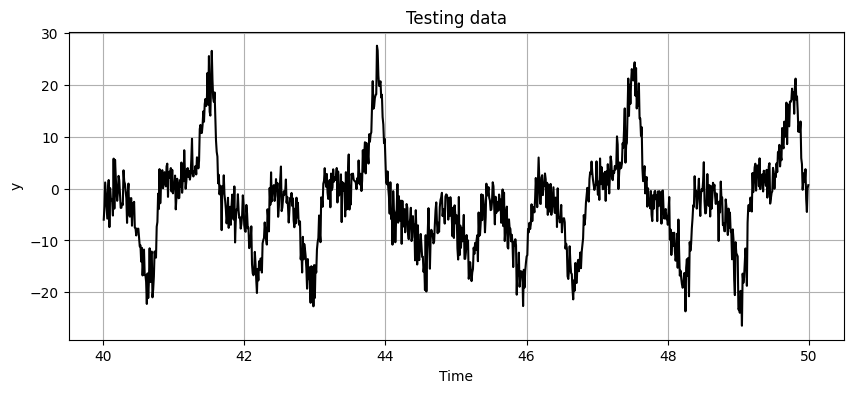

In [10]:
t_axis = all_t[(len(all_t)-len(target_data_test)):len(all_t)]
plt.figure(figsize=(10, 4))
plt.plot(t_axis, target_data_test, color="black")
plt.xlabel("Time")
plt.ylabel("y")
plt.title("Testing data")
plt.grid(True)
plt.savefig("lorenz63_noisy_test.pdf", bbox_inches="tight")
plt.show()

In [11]:
import os
os.getcwd()

os.makedirs("results/lorenz/datasets", exist_ok=True)
print("Current directory:", os.getcwd())

Current directory: /kaggle/working/PF-GN-SR


In [12]:
%%bash
cd /kaggle/working/PF-GN-SR/

# --- Running Deterministic Regression ---
python3 train_nn.py lorenz regression --lr 0.001 --epochs 1000 --seed 12 --batch_size 1000 --hidden_size_rnn 8
python3 predict_test_plot.py lorenz regression --lr 0.001 --seed 12 --batch_size 1000 --hidden_size_rnn 8 --plot_start_timestep 0 --plot_end_timestep 999

Train regression network for lorenz model with lr 0.001 
Test regression network for lorenz model using Energy scoring rule
Calibration metrics:
x0: Cal. error 0.5050, RMSE 0.0583, R2 0.8807

Average values: Cal. error 0.5050, RMSE 0.0583, R2 0.8807

Standard deviation: Cal. error 0.0000, RMSE 0.0000, R2 0.0000


Average values: Cal. error, RMSE, R2 
\n\t\t 0.5050 $ \pm$ 0.0000 & 0.0583  $ \pm$ 0.0000 &  0.8807 $ \pm$ 0.0000 \\\\ \n
		 0.5050  & 0.0583  &  0.8807  \\ 


[INFO] Successfully saved prediction arrays to results/lorenz/test_predictions_output.npz!


 50%|████▉     | 499/1000 [00:26<00:26, 18.86it/s]


In [13]:
data = np.load("results/lorenz/test_predictions_output.npz")

dr_ensemble_preds = data["predictions_ensemble"] # (999, 200, 1)  
dr_preds_median = np.median(dr_ensemble_preds, axis=1)
dr_preds_lower_95 = np.percentile(dr_ensemble_preds, 2.5, axis=1)
dr_preds_upper_95 = np.percentile(dr_ensemble_preds, 97.5, axis=1)

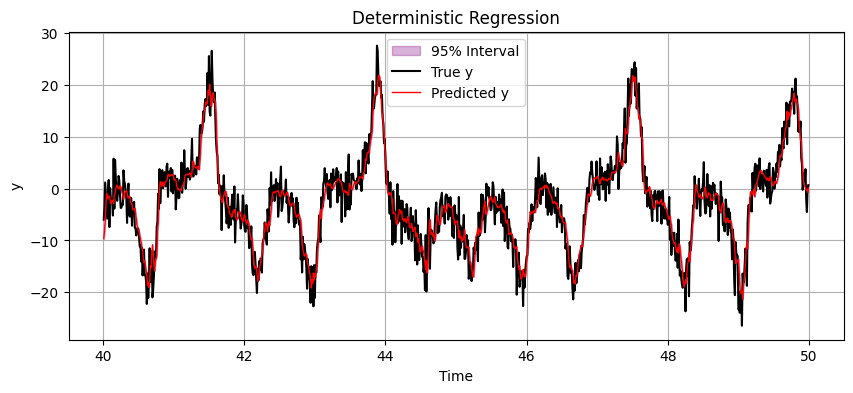

In [14]:
plt.figure(figsize=(10, 4))
t_axis = all_t[(len(all_t)-len(target_data_test)):len(all_t)]

# Ensure all arrays are 1D by removing extra dimensions
dr_lower_95 = np.squeeze(dr_preds_lower_95)
dr_upper_95 = np.squeeze(dr_preds_upper_95)
dr_median_pred = np.squeeze(dr_preds_median)

# Shade the 95% confidence interval
plt.fill_between(
    t_axis, 
    dr_lower_95, 
    dr_upper_95, 
    color='purple', 
    alpha=0.3, 
    label='95% Interval'
)

# Plot true values and predictions
plt.plot(t_axis, target_data_test, label='True y', color='black')
plt.plot(t_axis, dr_preds_median, label="Predicted y", color='red', linewidth=1)

plt.xlabel("Time")
plt.ylabel("y")
plt.title("Deterministic Regression")
plt.grid(True)
plt.legend()
plt.savefig("noise_deterministic_reg_plot.pdf", bbox_inches="tight")
plt.show()

In [15]:
%%bash
# --- SRs ---
# run the training script for Energy Score:
python3 train_nn.py lorenz SR --scoring_rule EnergyKernel --lr 0.01 --epochs 1000 --ensemble_size 10 --seed 12  --batch_size 1000 --hidden_size_rnn 8
# compute performance metrics and produce individual figures
python3 predict_test_plot.py lorenz SR --scoring_rule EnergyKernel --lr 0.01  --training_ensemble_size 10 --prediction_ensemble_size 200 --seed 12  --batch_size 1000 --hidden_size_rnn 8 --plot_start_timestep 0 --plot_end_timestep 999

Estimated gamma: 8.8077
Train SR network for lorenz model with lr 0.01 using EnergyKernel scoring rule
Test SR network for lorenz model using EnergyKernel scoring rule
Compute gamma...
Estimated gamma: 8.8077
VALIDATION
Whole data scores: 
Energy score: 3.65, Gaussian Kernel score -0.89, Rational quadratic Kernel score -0.21, Variogram score 0.00
TEST
Whole data scores: 
Energy score: 3.54, Gaussian Kernel score -0.89, Rational quadratic Kernel score -0.22, Variogram score 0.00

Calibration metrics:
x0: Cal. error 0.0100, RMSE 0.0582, R2 0.8811

Average values: Cal. error 0.0100, RMSE 0.0582, R2 0.8811

Standard deviation: Cal. error 0.0000, RMSE 0.0000, R2 0.0000


Average values: Cal. error, RMSE, R2 
\n\t\t 0.0100 $ \pm$ 0.0000 & 0.0582  $ \pm$ 0.0000 &  0.8811 $ \pm$ 0.0000 \\\\ \n
		 0.0100  & 0.0582  &  0.8811  \\ 


[INFO] Successfully saved prediction arrays to results/lorenz/test_predictions_output.npz!


 10%|▉         | 99/1000 [00:09<01:25, 10.55it/s]


In [16]:
data = np.load("results/lorenz/test_predictions_output.npz")

ekr_ensemble_preds = data["predictions_ensemble"] # (999, 200, 1)  
ekr_preds_median = np.median(ekr_ensemble_preds, axis=1)
ekr_preds_lower_95 = np.percentile(ekr_ensemble_preds, 2.5, axis=1)
ekr_preds_upper_95 = np.percentile(ekr_ensemble_preds, 97.5, axis=1)

plt.figure(figsize=(10, 4))
t_axis = all_t[(len(all_t)-len(target_data_test)):len(all_t)]

# Ensure all arrays are 1D by removing extra dimensions
ekr_lower_95 = np.squeeze(ekr_preds_lower_95)
ekr_upper_95 = np.squeeze(ekr_preds_upper_95)
ekr_median_pred = np.squeeze(ekr_preds_median)

<Figure size 1000x400 with 0 Axes>

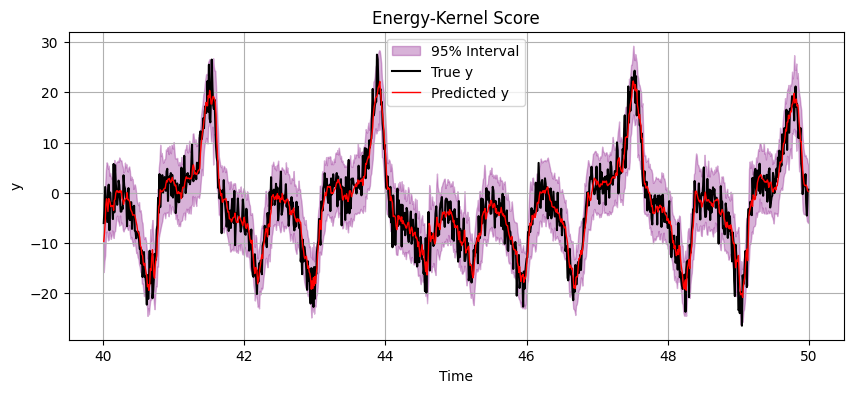

In [17]:
# Shade the 95% confidence interval
plt.figure(figsize=(10, 4))
plt.fill_between(
    t_axis, 
    ekr_lower_95, 
    ekr_upper_95, 
    color='purple', 
    alpha=0.3, 
    label='95% Interval'
)

# Plot true values and predictions
plt.plot(t_axis, target_data_test, label='True y', color='black')
plt.plot(t_axis, ekr_preds_median, label="Predicted y", color='red', linewidth=1)

plt.xlabel("Time")
plt.ylabel("y")
plt.title("Energy-Kernel Score")
plt.grid(True)
plt.legend()
plt.savefig("noise_enery_kernel_score_plot.pdf", bbox_inches="tight")
plt.show()

In [18]:
%%bash
# --- SRs ---
# run the training script for Energy Score:
python3 train_nn.py lorenz SR --scoring_rule Energy --lr 0.01 --epochs 1000 --ensemble_size 10 --seed 12  --batch_size 1000 --hidden_size_rnn 8
# compute performance metrics and produce individual figures
python3 predict_test_plot.py lorenz SR --scoring_rule Energy --lr 0.01  --training_ensemble_size 10 --prediction_ensemble_size 200 --seed 12  --batch_size 1000 --hidden_size_rnn 8 --plot_start_timestep 0 --plot_end_timestep 999

Train SR network for lorenz model with lr 0.01 using Energy scoring rule
Test SR network for lorenz model using Energy scoring rule
Compute gamma...
Estimated gamma: 8.8077
VALIDATION
Whole data scores: 
Energy score: 3.63, Gaussian Kernel score -0.89, Rational quadratic Kernel score -0.22, Variogram score 0.00
TEST
Whole data scores: 
Energy score: 3.55, Gaussian Kernel score -0.89, Rational quadratic Kernel score -0.22, Variogram score 0.00

Calibration metrics:
x0: Cal. error 0.0130, RMSE 0.0582, R2 0.8811

Average values: Cal. error 0.0130, RMSE 0.0582, R2 0.8811

Standard deviation: Cal. error 0.0000, RMSE 0.0000, R2 0.0000


Average values: Cal. error, RMSE, R2 
\n\t\t 0.0130 $ \pm$ 0.0000 & 0.0582  $ \pm$ 0.0000 &  0.8811 $ \pm$ 0.0000 \\\\ \n
		 0.0130  & 0.0582  &  0.8811  \\ 


[INFO] Successfully saved prediction arrays to results/lorenz/test_predictions_output.npz!


 10%|▉         | 99/1000 [00:07<01:04, 13.90it/s]


In [19]:
data = np.load("results/lorenz/test_predictions_output.npz")

sr_ensemble_preds = data["predictions_ensemble"] # (999, 200, 1)  
sr_preds_median = np.median(sr_ensemble_preds, axis=1)
sr_preds_lower_95 = np.percentile(sr_ensemble_preds, 2.5, axis=1)
sr_preds_upper_95 = np.percentile(sr_ensemble_preds, 97.5, axis=1)

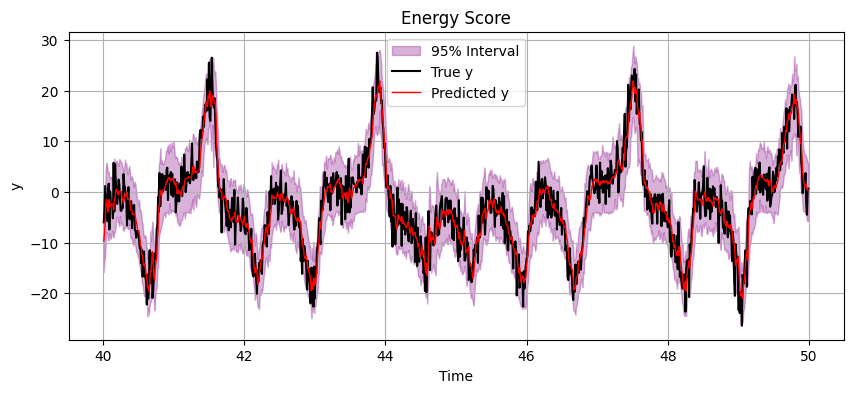

In [20]:
plt.figure(figsize=(10, 4))
t_axis = all_t[(len(all_t)-len(target_data_test)):len(all_t)]

# Ensure all arrays are 1D by removing extra dimensions
sr_lower_95 = np.squeeze(sr_preds_lower_95)
sr_upper_95 = np.squeeze(sr_preds_upper_95)
sr_median_pred = np.squeeze(sr_preds_median)

# Shade the 95% confidence interval
plt.fill_between(
    t_axis, 
    sr_lower_95, 
    sr_upper_95, 
    color='purple', 
    alpha=0.3, 
    label='95% Interval'
)

# Plot true values and predictions
plt.plot(t_axis, target_data_test, label='True y', color='black')
plt.plot(t_axis, sr_preds_median, label="Predicted y", color='red', linewidth=1)

plt.xlabel("Time")
plt.ylabel("y")
plt.title("Energy Score")
plt.grid(True)
plt.legend()
plt.savefig("noise_energy_score_plot.pdf", bbox_inches="tight")
plt.show()

In [21]:
%%bash
# --- SRs ---
# run the training script for Energy Score:
python3 train_nn.py lorenz SR --scoring_rule Kernel --lr 0.01 --epochs 1000 --ensemble_size 10 --seed 12  --batch_size 1000 --hidden_size_rnn 8
# compute performance metrics and produce individual figures
python3 predict_test_plot.py lorenz SR --scoring_rule Kernel --lr 0.01  --training_ensemble_size 10 --prediction_ensemble_size 200 --seed 12  --batch_size 1000 --hidden_size_rnn 8 --plot_start_timestep 0 --plot_end_timestep 999

Estimated gamma: 8.8077
Train SR network for lorenz model with lr 0.01 using Kernel scoring rule
Test SR network for lorenz model using Kernel scoring rule
Compute gamma...
Estimated gamma: 8.8077
VALIDATION
Whole data scores: 
Energy score: 3.61, Gaussian Kernel score -0.89, Rational quadratic Kernel score -0.22, Variogram score 0.00
TEST
Whole data scores: 
Energy score: 3.53, Gaussian Kernel score -0.89, Rational quadratic Kernel score -0.22, Variogram score 0.00

Calibration metrics:
x0: Cal. error 0.0220, RMSE 0.0581, R2 0.8813

Average values: Cal. error 0.0220, RMSE 0.0581, R2 0.8813

Standard deviation: Cal. error 0.0000, RMSE 0.0000, R2 0.0000


Average values: Cal. error, RMSE, R2 
\n\t\t 0.0220 $ \pm$ 0.0000 & 0.0581  $ \pm$ 0.0000 &  0.8813 $ \pm$ 0.0000 \\\\ \n
		 0.0220  & 0.0581  &  0.8813  \\ 


[INFO] Successfully saved prediction arrays to results/lorenz/test_predictions_output.npz!


 12%|█▏        | 124/1000 [00:09<01:10, 12.51it/s]


In [22]:
data = np.load("results/lorenz/test_predictions_output.npz")

kr_ensemble_preds = data["predictions_ensemble"] # (999, 200, 1)  
kr_preds_median = np.median(kr_ensemble_preds, axis=1)
kr_preds_lower_95 = np.percentile(kr_ensemble_preds, 2.5, axis=1)
kr_preds_upper_95 = np.percentile(kr_ensemble_preds, 97.5, axis=1)

plt.figure(figsize=(10, 4))
t_axis = all_t[(len(all_t)-len(target_data_test)):len(all_t)]

<Figure size 1000x400 with 0 Axes>

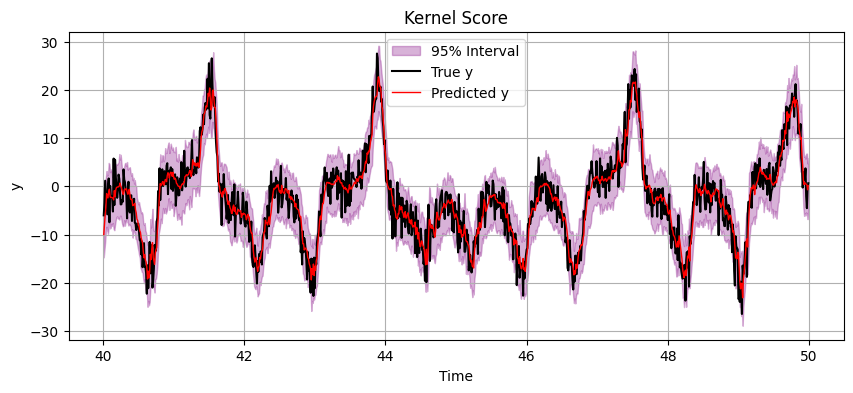

In [23]:
# Ensure all arrays are 1D by removing extra dimensions
kr_lower_95 = np.squeeze(kr_preds_lower_95)
kr_upper_95 = np.squeeze(kr_preds_upper_95)
kr_median_pred = np.squeeze(kr_preds_median)

plt.figure(figsize=(10, 4))
# Shade the 95% confidence interval
plt.fill_between(
    t_axis, 
    kr_lower_95, 
    kr_upper_95, 
    color='purple', 
    alpha=0.3, 
    label='95% Interval'
)

# Plot true values and predictions
plt.plot(t_axis, target_data_test, label='True y', color='black')
plt.plot(t_axis, kr_preds_median, label="Predicted y", color='red', linewidth=1)

plt.xlabel("Time")
plt.ylabel("y")
plt.title("Kernel Score")
plt.grid(True)
plt.legend()
plt.savefig("noise_kernel_score_plot.pdf", bbox_inches="tight")
plt.show()

In [24]:
%%bash
# --- GANs ---
# run the training script for GAN:
python3 train_nn.py lorenz GAN --lr 0.0001 --lr_c 0.001 --epochs 1000 --seed 12  --batch_size 1000 --hidden_size_rnn 8
# compute performance metrics and produce individual figures
python3 predict_test_plot.py lorenz GAN --lr 0.0001 --lr_c 0.001  --prediction_ensemble_size 200 --seed 12 --hidden_size_rnn 8  --batch_size 1000 --plot_start_timestep 0 --plot_end_timestep 999

Train GAN network for lorenz model with lr 0.0001 and critic lr 0.001
Test GAN network for lorenz model
Compute gamma...
Estimated gamma: 8.8077
VALIDATION
Whole data scores: 
Energy score: 7.89, Gaussian Kernel score -0.67, Rational quadratic Kernel score 0.01, Variogram score 0.00
TEST
Whole data scores: 
Energy score: 10.58, Gaussian Kernel score -0.54, Rational quadratic Kernel score 0.18, Variogram score 0.00

Calibration metrics:
x0: Cal. error 0.2950, RMSE 0.1449, R2 0.2619

Average values: Cal. error 0.2950, RMSE 0.1449, R2 0.2619

Standard deviation: Cal. error 0.0000, RMSE 0.0000, R2 0.0000


Average values: Cal. error, RMSE, R2 
\n\t\t 0.2950 $ \pm$ 0.0000 & 0.1449  $ \pm$ 0.0000 &  0.2619 $ \pm$ 0.0000 \\\\ \n
		 0.2950  & 0.1449  &  0.2619  \\ 


[INFO] Successfully saved prediction arrays to results/lorenz/test_predictions_output.npz!


100%|██████████| 1000/1000 [01:56<00:00,  8.60it/s]


In [25]:
data = np.load("results/lorenz/test_predictions_output.npz")

gan_ensemble_preds = data["predictions_ensemble"] # (999, 200, 1)  
gan_preds_median = np.median(gan_ensemble_preds, axis=1)
gan_preds_lower_95 = np.percentile(gan_ensemble_preds, 2.5, axis=1)
gan_preds_upper_95 = np.percentile(gan_ensemble_preds, 97.5, axis=1)

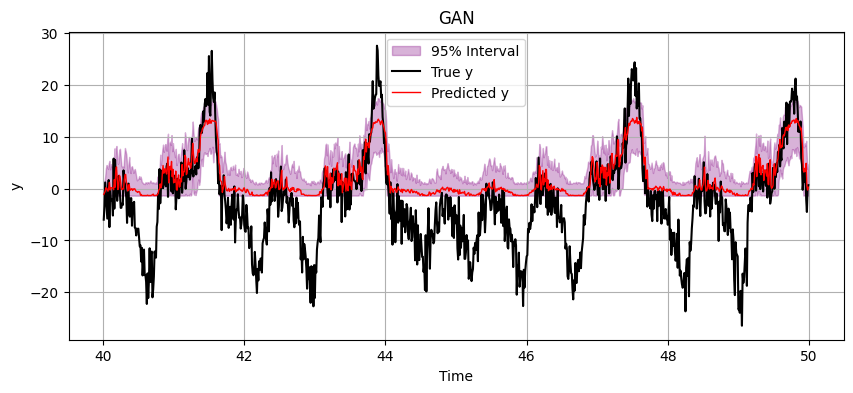

In [26]:
plt.figure(figsize=(10, 4))
t_axis = all_t[(len(all_t)-len(target_data_test)):len(all_t)]

# Ensure all arrays are 1D by removing extra dimensions
gan_lower_95 = np.squeeze(gan_preds_lower_95)
gan_upper_95 = np.squeeze(gan_preds_upper_95)
gan_median_pred = np.squeeze(gan_preds_median)

# Shade the 95% confidence interval
plt.fill_between(
    t_axis, 
    gan_lower_95, 
    gan_upper_95, 
    color='purple', 
    alpha=0.3, 
    label='95% Interval'
)

# Plot true values and predictions
plt.plot(t_axis, target_data_test, label='True y', color='black')
plt.plot(t_axis, gan_median_pred, label="Predicted y", color='red', linewidth=1)

plt.xlabel("Time")
plt.ylabel("y")
plt.title("GAN")
plt.grid(True)
plt.legend()
plt.savefig("noise_gan_plot.pdf", bbox_inches="tight")
plt.show()

In [27]:
timeseries_stacked = None
window_size = 10
if timeseries_stacked is None:  # if that is not created above (as for the Lorenz96)
    timeseries_stacked = np.lib.stride_tricks.sliding_window_view(timeseries, window_shape=window_size + 1,
                                                                  axis=0).transpose(0, 2, 1)

# Then, we can split in input, target as follows:
input_data = timeseries_stacked[:, 0:-1]
target_data = timeseries_stacked[:, -1]
n_samples = input_data.shape[0]
print("Total number of samples:", n_samples)

# train/validate/test (60-20-20) split, in order (not shuffling):
n_train = int(0.6 * n_samples)
n_val = int(0.2 * n_samples)-1
n_test = n_samples - n_val - n_train

input_data_train = input_data[0:n_train + n_val]
target_data_train = target_data[0:n_train + n_val]
input_data_test = input_data[n_train + n_val:n_samples]
target_data_test = target_data[n_train + n_val:n_samples]

input_data_train.shape

Total number of samples: 4990


(3991, 10, 1)

In [28]:
def smooth_pandas(arr, window_size=3):
  series = pd.Series(arr)
  # min_periods=1 ensures the first and last elements (tails) are computed instead of NaN
  smoothed = series.rolling(
      window=window_size, center=True, min_periods=1
  ).mean()
  return smoothed.to_numpy()
    
delta_t = 0.01
m = window_size
y_prime = (target_data.squeeze() - input_data.squeeze()[:, m - 1]) / delta_t

X_train = input_data_train.squeeze()
y_train = target_data_train.squeeze()
y_prime_train = y_prime[:n_train+n_val]

# Standardize (ddof=1 matches R's sample standard deviation sd())
y_mean = np.mean(y_prime_train)
y_sd = np.std(y_prime_train, ddof=1)
y_prime_train_scaled = (y_prime_train - y_mean) / y_sd
y_prime_train_scaled_smooth = smooth_pandas(y_prime_train_scaled, window_size=12) 
smooth_var = np.mean((y_prime_train_scaled - y_prime_train_scaled_smooth) ** 2)

X_test = input_data_test.squeeze()
y_test = target_data_test.squeeze() 
y_prime_test = y_prime[n_train+n_val:n_samples]

In [29]:
print(smooth_var)
print(np.mean(y_prime_train_scaled - y_prime_train_scaled_smooth))

0.9825686958646983
-4.385378685973104e-05


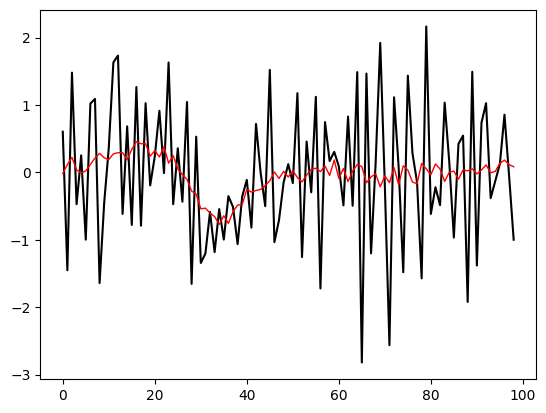

In [30]:
plt.plot(y_prime_train_scaled[1:100], label='True y', color='black')
plt.plot(y_prime_train_scaled_smooth[1:100], label="Predicted y", color='red', linewidth=1)

In [31]:
# ==========================================
# --- Step 2: Random Fourier Features ---
# ==========================================
D = 5000

# Weighting matrix & Bias vector
W = np.random.normal(loc=0.0, scale=1.0, size=(m, D))
b = np.random.uniform(low=0.0, high=1.0, size=(1, D))

# Transformation (NumPy broadcasts `b` across rows automatically)
Z_train = X_train @ W + b
Z_test = X_test @ W + b

# Activation function
act_fn_train = np.sqrt(2.0 / D) * np.cos(Z_train)
act_fn_test = np.sqrt(2.0 / D) * np.cos(Z_test)

In [32]:
# ==========================================
# --- Step 3: Helper & Loss Functions ---
# ==========================================
def crps_gaussian(mu, sigma, y_obs):
    z = (y_obs - mu) / sigma
    crps_val = sigma * (z * (2.0 * stats.norm.cdf(z) - 1.0) + 2.0 * stats.norm.pdf(z) - 1.0 / np.sqrt(np.pi))
    return crps_val

def eval_crps_loss(beta_0, beta, sigma, Z_mat, y_target):
    mu = beta_0 + Z_mat @ beta
    return np.mean(crps_gaussian(mu=mu, sigma=sigma, y_obs=y_target))

def update_lambda_sq(tau_sq, sigma_sq, beta):
    mu_ig = np.sqrt((2.0 * tau_sq * sigma_sq) / (beta ** 2))
    # statmod::rinvgauss(mean=mu_ig, shape=2) matches np.random.wald(mean=mu_ig, scale=2)
    inv_lambda_sq = np.random.wald(mean=mu_ig, scale=2.0, size=len(beta))
    return 1.0 / inv_lambda_sq

def update_tau_sq(D, xi, sigma_sq, beta, lambda_sq):
    scale = (1.0 / xi) + (1.0 / (2.0 * sigma_sq)) * np.sum((beta ** 2) / lambda_sq)
    # Inv-Gamma(shape, scale) is equivalent to 1 / Gamma(shape, rate=scale)
    return 1.0 / np.random.gamma(shape=(D + 1.0) / 2.0, scale=1.0 / scale)

def update_xi(tau_sq):
    scale = 1.0 + 1.0 / tau_sq
    return 1.0 / np.random.gamma(shape=1.0, scale=1.0 / scale)

In [33]:
# ==========================================
# --- Step 4: Block MCMC Sampling ---
# ==========================================
S = 5000
B = 2500

# Set eta on the average CRPS scale
eta = 1.0

# Step sizes
step_b0  = 3.0   # 3
step_sig = 0.05  # 0.04, 0.03
c_beta   = 0.5   # 0.03, 0.02

# Initializations
# beta_0       = float(np.mean(y_prime_train_scaled))
beta_0       = float(np.mean(y_prime_train_scaled_smooth))
beta         = np.zeros(D)
log_sigma_sq = np.log(1e-6)  # np.log(1.0)
sigma_sq     = np.exp(log_sigma_sq)

lambda_sq = np.ones(D)
tau_sq    = 1.0
xi_val    = 1.0

# Maintain linear predictor (Z_train @ beta)
Z_beta = Z_train @ beta
# current_loss = np.mean(crps_gaussian(mu=beta_0 + Z_beta, sigma=np.sqrt(sigma_sq), y_obs=y_prime_train_scaled))
current_loss = np.mean(crps_gaussian(mu=beta_0 + Z_beta, sigma=np.sqrt(sigma_sq), y_obs=y_prime_train_scaled_smooth))

n_save = S - B
post_beta_0   = np.zeros(n_save)
post_beta     = np.zeros((n_save, D))
post_sigma_sq = np.zeros(n_save)

# Initial tracking counters
accepted_beta_blocks = 0
total_beta_proposals = 0
accepted_b0          = 0
accepted_sig         = 0

# Pre-set block size for beta updates
block_size = 5

for s in range(1, S + 1):
    
    # =========================================================================
    # 1. Block A: Subspace / Block Metropolis Update for beta
    # =========================================================================
    prior_var = lambda_sq * tau_sq * sigma_sq
    # prior_var = np.where(~np.isfinite(prior_var) | (prior_var <= 0), 1e-10, prior_var)
    prior_sd  = np.sqrt(prior_var)
    
    # Ensure proposal standard deviation has a non-zero floor
    # step_sd = np.maximum(c_beta * prior_sd, 1e-4)
    # step_sd = np.where(~np.isfinite(step_sd), 1e-4, step_sd)
    step_sd = c_beta * prior_sd

    # Update beta in randomized coordinate blocks to avoid joint rejection
    shuffled_indices = np.random.permutation(D)
    block_starts     = range(0, D, block_size)
    sigma_curr       = np.sqrt(sigma_sq)
    
    for b_start in block_starts:
        idx_b = shuffled_indices[b_start : min(b_start + block_size, D)]
        total_beta_proposals += 1
        
        # Propose only for the block coordinates
        cand_beta_b = np.random.normal(loc=beta[idx_b], scale=step_sd[idx_b])
        
        # Fast rank-5 update of linear predictor (mathematically identical to Z_train @ cand_beta)
        cand_Z_beta = Z_beta + Z_train[:, idx_b] @ (cand_beta_b - beta[idx_b])
        # cand_loss_beta = np.mean(crps_gaussian(mu=beta_0 + cand_Z_beta, sigma=sigma_curr, y_obs=y_prime_train_scaled))
        cand_loss_beta = np.mean(crps_gaussian(mu=beta_0 + cand_Z_beta, sigma=sigma_curr, y_obs=y_prime_train_scaled_smooth))
        
        # (Note: If you ever want the slow full-matrix version instead, use:
        #  cand_beta = beta.copy(); cand_beta[idx_b] = cand_beta_b
        #  cand_loss_beta = eval_crps_loss(beta_0, cand_beta, sigma_curr, Z_train, y_prime_train_scaled))
        
        diff_log_prior = -0.5 * np.sum((cand_beta_b**2 - beta[idx_b]**2) / (prior_sd[idx_b]**2))
        log_alpha_beta = -eta * (cand_loss_beta - current_loss) + diff_log_prior
        
        if np.isfinite(log_alpha_beta) and np.log(np.random.uniform()) < log_alpha_beta:
            beta[idx_b]          = cand_beta_b
            Z_beta               = cand_Z_beta
            current_loss         = cand_loss_beta
            accepted_beta_blocks += 1

    # =========================================================================
    # 2. Block B1: Propose beta_0 (Flat Improper Prior pi(beta_0) propto 1)
    # =========================================================================
    cand_beta_0  = np.random.normal(loc=beta_0, scale=step_b0)
    # cand_loss_b0 = np.mean(crps_gaussian(mu=cand_beta_0 + Z_beta, sigma=np.sqrt(sigma_sq), y_obs=y_prime_train_scaled))
    cand_loss_b0 = np.mean(crps_gaussian(mu=cand_beta_0 + Z_beta, sigma=np.sqrt(sigma_sq), y_obs=y_prime_train_scaled_smooth))
    
    # Uniform prior ratio is log(1) = 0
    log_alpha_b0 = -eta * (cand_loss_b0 - current_loss)
    
    if np.isfinite(log_alpha_b0) and np.log(np.random.uniform()) < log_alpha_b0:
        beta_0       = cand_beta_0
        current_loss = cand_loss_b0
        accepted_b0  += 1

    # =========================================================================
    # 3. Block B2: Propose log_sigma_sq
    # =========================================================================
    cand_log_sig_sq = np.random.normal(loc=log_sigma_sq, scale=step_sig)
    # Clip log_sigma to prevent exp() overflow
    # cand_log_sig_sq = np.clip(cand_log_sig_sq, -20.0, 20.0)
    cand_sigma_sq   = np.exp(cand_log_sig_sq)
    
    # cand_loss_sig   = np.mean(crps_gaussian(mu=beta_0 + Z_beta, sigma=np.sqrt(cand_sigma_sq), y_obs=y_prime_train_scaled))
    cand_loss_sig   = np.mean(crps_gaussian(mu=beta_0 + Z_beta, sigma=np.sqrt(cand_sigma_sq), y_obs=y_prime_train_scaled_smooth))
    # cand_prior_sd = np.sqrt(np.maximum(lambda_sq * tau_sq * cand_sigma_sq, 1e-10))
    cand_prior_sd   = np.sqrt(lambda_sq * tau_sq * cand_sigma_sq)
    
    log_prior_sig_curr = -0.5 * np.sum(np.log(prior_sd**2) + (beta**2) / (prior_sd**2)) - log_sigma_sq
    log_prior_sig_cand = -0.5 * np.sum(np.log(cand_prior_sd**2) + (beta**2) / (cand_prior_sd**2)) - cand_log_sig_sq
    
    log_alpha_sig = (-eta * cand_loss_sig + log_prior_sig_cand) - (-eta * current_loss  + log_prior_sig_curr)
                    
    if np.isfinite(log_alpha_sig) and np.log(np.random.uniform()) < log_alpha_sig:
        log_sigma_sq = cand_log_sig_sq
        sigma_sq     = cand_sigma_sq
        prior_sd     = cand_prior_sd
        current_loss = cand_loss_sig
        accepted_sig += 1

    # =========================================================================
    # 4. Block C: Exact Gibbs Updates for Latent Scales (with safeguards)
    # =========================================================================
    # lambda_j^2 ~ Inv-Gaussian (NOTE: if beta has exact zeros on iter 1, add 1e-10 to beta**2)
    mu_ig   = np.sqrt((2.0 * tau_sq * sigma_sq) / (beta**2 + 1e-10))
    # mu_ig     = np.sqrt((2.0 * tau_sq * sigma_sq) / (beta**2))
    inv_lam   = np.random.wald(mean=mu_ig, scale=2.0, size=D)
    # lambda_sq = 1.0 / np.maximum(inv_lam, 1e-10)
    lambda_sq = 1.0 / inv_lam

    # tau^2 ~ Inv-Gamma
    shape_tau = (D + 1.0) / 2.0
    rate_tau  = (1.0 / xi_val) + (1.0 / (2.0 * sigma_sq)) * np.sum((beta**2) / lambda_sq)
    # tau_sq  = 1.0 / np.random.gamma(shape=shape_tau, scale=1.0 / max(rate_tau, 1e-10))
    tau_sq    = 1.0 / np.random.gamma(shape=shape_tau, scale=1.0 / rate_tau)

    # Mixing hyperparameter: xi ~ Inv-Gamma
    rate_xi   = 1.0 + (1.0 / tau_sq)
    # xi_val  = 1.0 / np.random.gamma(shape=1.0, scale=1.0 / max(rate_xi, 1e-10))
    xi_val    = 1.0 / np.random.gamma(shape=1.0, scale=1.0 / rate_xi)

    # =========================================================================
    # 5. Save Draws Post Burn-in
    # =========================================================================
    if s > B:
        idx = s - B - 1
        post_beta_0[idx]   = beta_0
        post_beta[idx, :]  = beta
        post_sigma_sq[idx] = sigma_sq

    if s % 200 == 0:
        print(f"Iter {s:4d} | Beta Block Acc: {(accepted_beta_blocks / total_beta_proposals) * 100:.1f}% | "
              f"Acc b0: {(accepted_b0 / s) * 100:.1f}% | Acc Sig: {(accepted_sig / s) * 100:.1f}%")

Iter  200 | Beta Block Acc: 60.0% | Acc b0: 46.0% | Acc Sig: 40.5%
Iter  400 | Beta Block Acc: 59.9% | Acc b0: 45.2% | Acc Sig: 38.0%
Iter  600 | Beta Block Acc: 59.9% | Acc b0: 44.3% | Acc Sig: 41.0%
Iter  800 | Beta Block Acc: 60.0% | Acc b0: 44.4% | Acc Sig: 43.0%
Iter 1000 | Beta Block Acc: 60.0% | Acc b0: 44.0% | Acc Sig: 42.9%
Iter 1200 | Beta Block Acc: 60.0% | Acc b0: 43.6% | Acc Sig: 42.7%
Iter 1400 | Beta Block Acc: 60.0% | Acc b0: 42.9% | Acc Sig: 43.1%
Iter 1600 | Beta Block Acc: 60.0% | Acc b0: 43.1% | Acc Sig: 43.1%
Iter 1800 | Beta Block Acc: 60.0% | Acc b0: 43.1% | Acc Sig: 43.1%
Iter 2000 | Beta Block Acc: 60.0% | Acc b0: 43.0% | Acc Sig: 43.0%
Iter 2200 | Beta Block Acc: 60.0% | Acc b0: 42.9% | Acc Sig: 42.7%
Iter 2400 | Beta Block Acc: 60.0% | Acc b0: 43.7% | Acc Sig: 42.7%
Iter 2600 | Beta Block Acc: 60.0% | Acc b0: 43.2% | Acc Sig: 42.5%
Iter 2800 | Beta Block Acc: 60.0% | Acc b0: 43.5% | Acc Sig: 42.5%
Iter 3000 | Beta Block Acc: 60.0% | Acc b0: 43.8% | Acc Sig: 4

ESS Beta 0: 430.030323645447


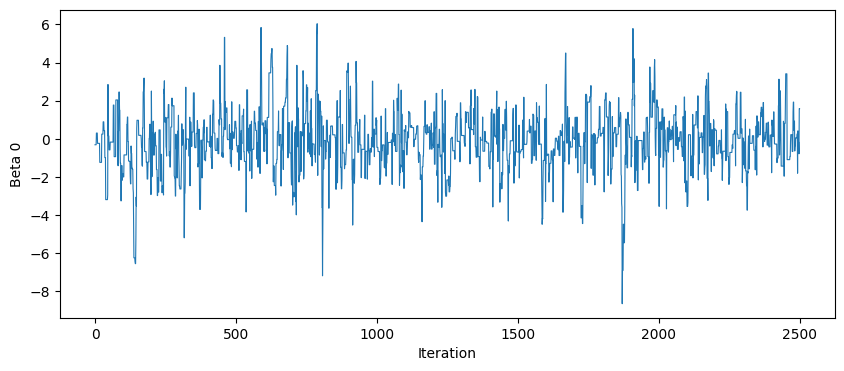

In [34]:
# ==========================================
# --- Diagnostics & Trace Plots ---
# ==========================================
def compute_ess(samples):
    """Computes Effective Sample Size across 1D or 2D (n_draws, n_params) array."""
    if samples.ndim == 1:
        return float(az.ess(samples))
    return np.array([az.ess(samples[:, j]) for j in range(samples.shape[1])])

# Beta 0
ess_beta_0 = compute_ess(post_beta_0)
print("ESS Beta 0:", ess_beta_0)

plt.figure(figsize=(10, 4))
plt.plot(post_beta_0, lw=0.8)
plt.xlabel("Iteration")
plt.ylabel("Beta 0")
plt.savefig("noise_post_beta_0.pdf", bbox_inches="tight")
plt.show()

ESS Sigma sq: 6.350640232488432


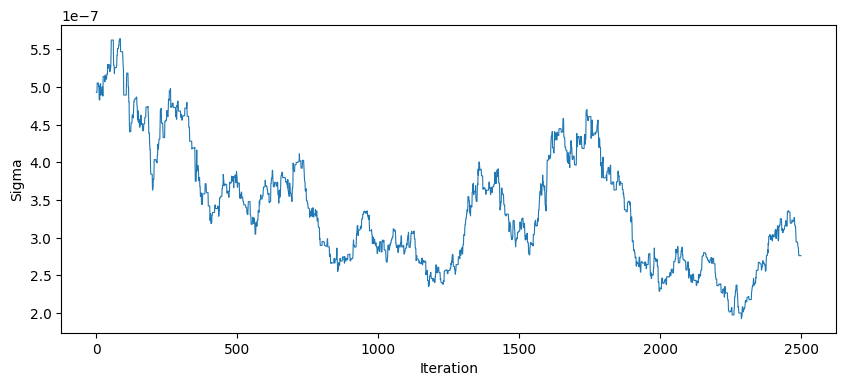

In [35]:
# Sigma sq
ess_sigma_sq = compute_ess(post_sigma_sq)
print("ESS Sigma sq:", ess_sigma_sq)

plt.figure(figsize=(10, 4))
plt.plot(post_sigma_sq, lw=0.8)
plt.xlabel("Iteration")
plt.ylabel("Sigma")
plt.savefig("noise_post_sigma.pdf", bbox_inches="tight")
plt.show()

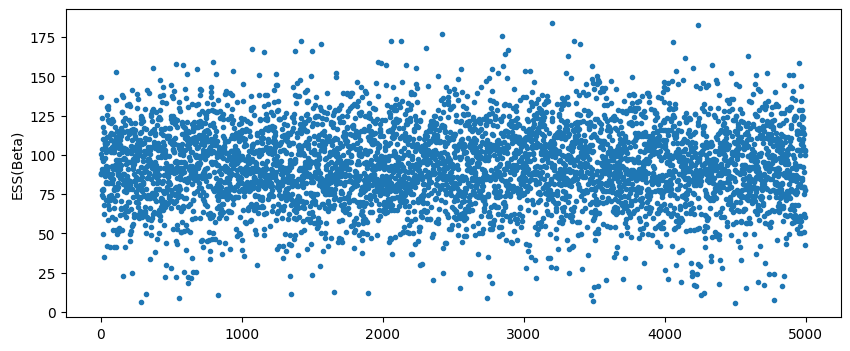

In [36]:
# Beta
ess_beta = compute_ess(post_beta)
plt.figure(figsize=(10, 4))
plt.plot(ess_beta, 'o', markersize=3)
plt.ylabel("ESS(Beta)")
plt.savefig("noise_ess_beta.pdf", bbox_inches="tight")
plt.show()

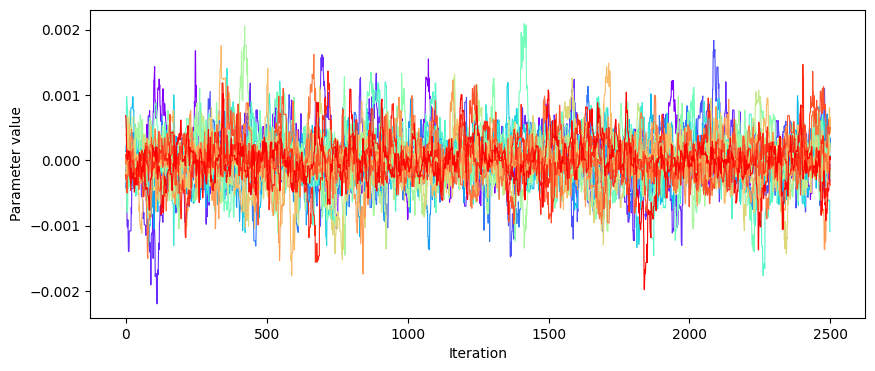

In [37]:
n_cols = post_beta.shape[1]
idx = np.random.choice(n_cols, size=min(20, n_cols), replace=False)

plt.figure(figsize=(10, 4))
colors = plt.cm.rainbow(np.linspace(0, 1, len(idx)))
for i, col_idx in enumerate(idx):
    plt.plot(post_beta[:, col_idx], color=colors[i], lw=0.8)
plt.xlabel("Iteration")
plt.ylabel("Parameter value")
plt.savefig("noise_post_beta.pdf", bbox_inches="tight")
plt.show()

In [38]:
# Summary & Quantiles of ESS
ess_series = pd.Series(ess_beta)
print(ess_series.describe())
print(np.quantile(ess_beta, [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]))

count    5000.000000
mean       92.859997
std        25.305535
min         5.457918
25%        76.861583
50%        92.604998
75%       109.631416
max       183.889447
dtype: float64
[  5.45791788  61.6367817   76.86158284  92.60499756 109.63141641
 124.25455155 183.8894472 ]


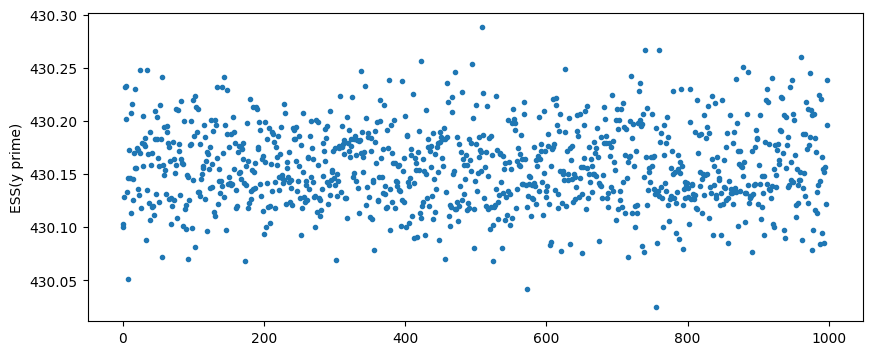

In [39]:
# ==========================================
# --- Step 5: Posterior Predictive & Plot ---
# ==========================================
n_draws = n_save
eps_noise = np.random.normal(loc=0.0, scale=np.sqrt(post_sigma_sq))

# Reshape 1D vectors to (n_draws, 1) to match R's column-wise vector addition
y_prime_scaled_draws = post_beta_0[:, None] + (post_beta @ act_fn_test.T) + eps_noise[:, None]

ess_y_prime = compute_ess(y_prime_scaled_draws)
plt.figure(figsize=(10, 4))
plt.plot(ess_y_prime, 'o', markersize=3)
plt.ylabel("ESS(y prime)")
plt.savefig("noise_ess_y_prime.pdf", bbox_inches="tight")
plt.show()

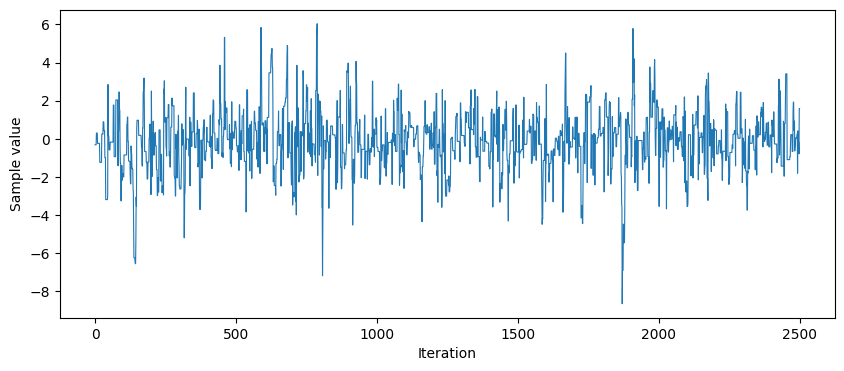

In [40]:
plt.figure(figsize=(10, 4))
plt.plot(y_prime_scaled_draws[:, 0], lw=0.8)
plt.xlabel("Iteration")
plt.ylabel("Sample value")
plt.savefig("noise_y_prime_scaled_draws.pdf", bbox_inches="tight")
plt.show()

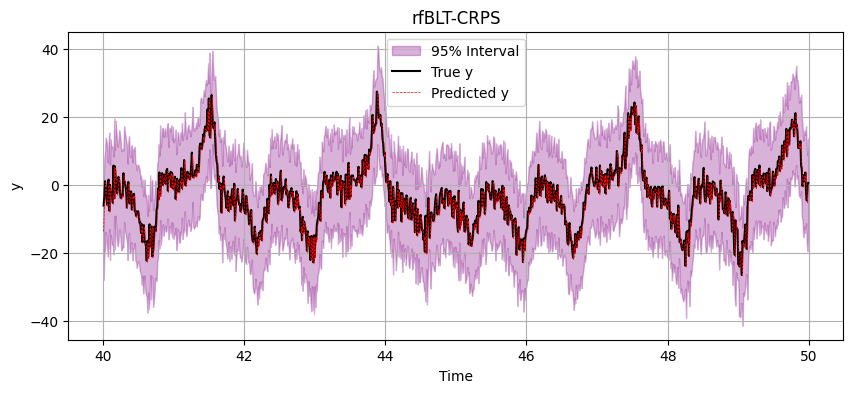

In [41]:
# Convert back to the original scale
smooth_noise = np.random.normal(
    loc=0.0, 
    scale=np.sqrt(smooth_var), 
    size=y_prime_scaled_draws.shape
)
y_prime_draws = (y_prime_scaled_draws + smooth_noise) * y_sd + y_mean

y_current = X_test[:, -1]
y_current_mat = np.tile(y_current[:, None], (1, n_save))
y_pred_draws = y_current_mat + (delta_t * y_prime_draws).T

# Point prediction & 95% Credible Interval
y_pred_median = np.median(y_pred_draws, axis=1)
y_pred_mean = np.mean(y_pred_draws, axis=1)
y_pred_ci = np.nanquantile(y_pred_draws, q=[0.025, 0.975], axis=1).T  # shape: (n_test, 2)

plt.figure(figsize=(10, 4))
t_axis = all_t[(len(all_t)-len(target_data_test)):len(all_t)]

# Ensure all arrays are 1D by removing extra dimensions
rfBLT_lower_95 = y_pred_ci[:, 0]
rfBLT_upper_95 = y_pred_ci[:, 1]

# Shade the 95% confidence interval
plt.fill_between(
    t_axis, 
    rfBLT_lower_95, 
    rfBLT_upper_95, 
    color='purple', 
    alpha=0.3, 
    label='95% Interval'
)

# Plot true values and predictions
plt.plot(t_axis, target_data_test, label='True y', color='black')
plt.plot(t_axis, y_pred_median, label="Predicted y", color='red', linewidth=0.5, linestyle='--')

plt.xlabel("Time")
plt.ylabel("y")
plt.title("rfBLT-CRPS")
plt.grid(True)
plt.legend()
plt.savefig("noise_rfBLT_plot.pdf", bbox_inches="tight")
plt.show()

In [42]:
# ==========================================
# --- Step 6: Evaluation Metrics ---
# ==========================================
rmse = np.sqrt(np.mean((y_test - y_pred_median) ** 2))
target_range = np.max(y_test) - np.min(y_test)
nrmse = rmse / target_range

y_bar = np.mean(y_test)
ss_res = np.sum((y_test - y_pred_median) ** 2)
ss_tot = np.sum((y_test - y_bar) ** 2)
r_squared = 1.0 - (ss_res / ss_tot)

print(f"Test RMSE:     {rmse}") # Median
print(f"Test NRMSE:    {nrmse}") # Median
print(f"Test R²:       {r_squared}") # Median

alphas = np.linspace(0.01, 0.99, 100)

alpha_star = []
for a in alphas:
    q_low = np.quantile(y_pred_draws, (1.0 - a) / 2.0, axis=1)
    q_upp = np.quantile(y_pred_draws, (1.0 + a) / 2.0, axis=1)
    alpha_star.append(np.mean((y_test >= q_low) & (y_test <= q_upp)))

alpha_star = np.array(alpha_star)

cal_error = np.median(np.abs(alpha_star - alphas))
print(f"Test Cal.error: {cal_error}")

Test RMSE:     3.8968353053412907
Test NRMSE:    0.07223054122730253
Test R²:       0.8166337490542243
Test Cal.error: 0.17434525434525433


In [43]:
rmse = np.sqrt(np.mean((y_test - y_pred_mean) ** 2))
target_range = np.max(y_test) - np.min(y_test)
nrmse = rmse / target_range

y_bar = np.mean(y_test)
ss_res = np.sum((y_test - y_pred_mean) ** 2)
ss_tot = np.sum((y_test - y_bar) ** 2)
r_squared = 1.0 - (ss_res / ss_tot)

print(f"Test RMSE:     {rmse}") # Mean
print(f"Test NRMSE:    {nrmse}") # Mean
print(f"Test R²:       {r_squared}") # Mean

alphas = np.linspace(0.01, 0.99, 100)

alpha_star = []
for a in alphas:
    q_low = np.quantile(y_pred_draws, (1.0 - a) / 2.0, axis=1)
    q_upp = np.quantile(y_pred_draws, (1.0 + a) / 2.0, axis=1)
    alpha_star.append(np.mean((y_test >= q_low) & (y_test <= q_upp)))

alpha_star = np.array(alpha_star)

cal_error = np.median(np.abs(alpha_star - alphas))
print(f"Test Cal.error: {cal_error}")

Test RMSE:     3.9057465380043817
Test NRMSE:    0.0723957170963918
Test R²:       0.8157941510092972
Test Cal.error: 0.17434525434525433
